In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate


file_path = r"C:\Users\ThinkPad\OneDrive - Dublin City University\Desktop\ML\fingers_crossed.csv"
df = pd.read_csv(file_path)
#df2 = pd.read_csv(file2_path)

# print(f"Rows: {df.shape[0]}")
# print(f"Columns: {df.shape[1]}")

# print(df2.head().to_string())
print(df.head().to_string())
# print(f"\nDuplicate rows: {df.duplicated().sum()}")
# print("\nSummary statistics:")
# print(df.describe(include="all").T.to_string())

# Select inputs without the target or saved row index.
feature_columns = [
    col for col in df.columns
    if col != "final_result"
    and not col.startswith("Unnamed:")
]

X = df[feature_columns].copy()

# Read the original three-class target
raw_result = pd.to_numeric(
    df["final_result"],
    errors="raise"
)

if raw_result.isna().any() or not raw_result.isin([0, 1, 2]).all():
    raise ValueError(
        f"Expected final_result values 0, 1 or 2. Found: "
        f"{raw_result.unique()}"
    )

# Convert to binary:
# 0 = Fail
# 1 = Pass/Distinction
y = raw_result.map({
    0: 0,
    1: 1,
    2: 1
}).astype(int)

class_names = ["Fail", "Pass/Distinction"]

if y.nunique() != 2:
    raise ValueError("The CSV must contain both outcome groups.")

# These columns represent categories
categorical_features = [
    "region",
    "highest_education",
    "imd_band",
    "age_band"
]

# All other inputs are numeric:
# scoreCA, credits, gender/disability flags and activity counts
numeric_features = [
    col for col in feature_columns
    if col not in categorical_features
]

X[categorical_features] = X[categorical_features].astype(str)

X[numeric_features] = X[numeric_features].apply(
    pd.to_numeric,
    errors="raise"
)

# Shared 80/20 split for both models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Each model will fit its own copy on the training data
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        )
    ],
    sparse_threshold=0
)


   Unnamed: 0  scoreCA  final_result                region  highest_education  imd_band  age_band  studied_credits  disability_N  disability_Y  gender_F  gender_M  dataplus  dualpane  externalquiz  folder  forumng  glossary  homepage  htmlactivity  oucollaborate  oucontent  ouelluminate  ouwiki  page  questionnaire  quiz  repeatactivity  resource  sharedsubpage  subpage   url
0           0     82.4           1.0   East Anglian Region                3.0      10.0       0.0              240           1.0           0.0       0.0       1.0       0.0       0.0           0.0     0.0    193.0       0.0     138.0           0.0            0.0      553.0           0.0     0.0   0.0            0.0   0.0             0.0      13.0            0.0     32.0   5.0
1           1     65.4           1.0              Scotland                3.0       3.0       1.0               60           1.0           0.0       1.0       0.0      10.0       0.0           0.0     0.0    417.0       0.0     324.0         

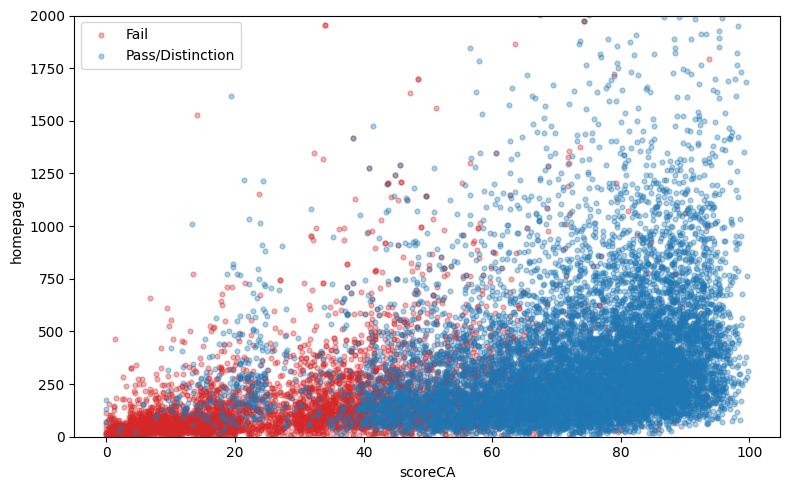

In [3]:
x_feature = "scoreCA"
y_feature = "homepage"

fig, ax = plt.subplots(figsize=(8, 5))

for label, colour in [(0, "tab:red"), (1, "tab:blue")]:
    mask = y_train == label

    ax.scatter(
        X_train.loc[mask, x_feature],
        X_train.loc[mask, y_feature],
        label=class_names[label],
        color=colour,
        alpha=0.35,
        s=12
    )

ax.set_xlabel(x_feature)
ax.set_ylabel(y_feature)
ax.legend()
ax.set_ylim(0, 2000)
plt.tight_layout()
plt.show()

In [4]:
tree_model = Pipeline([("preprocessor", clone(preprocessor)),("classifier", DecisionTreeClassifier(max_depth=7,min_samples_leaf=5, random_state=42))])

tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

tree_recall = recall_score(
    y_test, y_pred_tree, labels=[0, 1], average=None, zero_division=0
)

print(f"Test accuracy: {accuracy_score(y_test, y_pred_tree):.3f}")
print(f"Recall (Withdrawn/Fail): {tree_recall[0]:.3f}")
print(f"Recall (Pass/Distinction): {tree_recall[1]:.3f}")


Test accuracy: 0.867
Recall (Withdrawn/Fail): 0.718
Recall (Pass/Distinction): 0.935


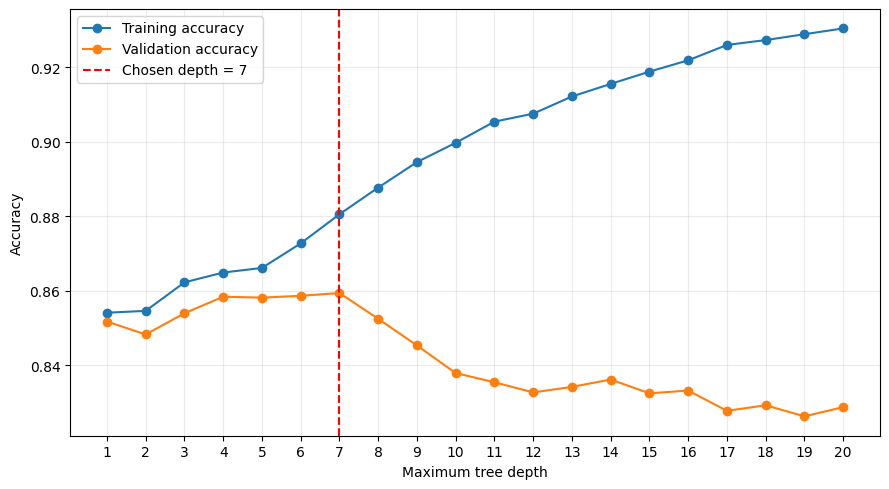

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

depths = list(range(1, 21))
training_accuracy = []
validation_accuracy = []

for depth in depths:
    depth_tree = clone(tree_model)
    depth_tree.set_params(classifier__max_depth=depth)
    depth_tree.fit(X_fit, y_fit)

    training_accuracy.append(depth_tree.score(X_fit, y_fit))
    validation_accuracy.append(depth_tree.score(X_val, y_val))

plt.figure(figsize=(9, 5))

plt.plot(
    depths, training_accuracy,
    marker="o", label="Training accuracy"
)
plt.plot(
    depths, validation_accuracy,
    marker="o", label="Validation accuracy"
)


plt.axvline(
    x=7,
    color="red",
    linestyle="--", label="Chosen depth = 7")

plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("elbow.png", dpi = 90)
plt.show()

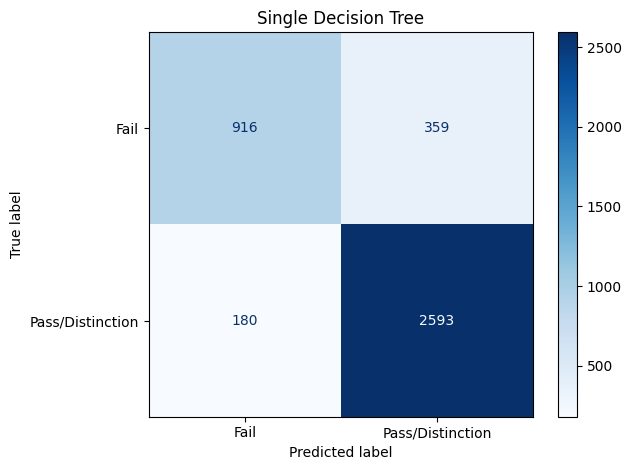

                  precision    recall  f1-score   support

            Fail      0.836     0.718     0.773      1275
Pass/Distinction      0.878     0.935     0.906      2773

        accuracy                          0.867      4048
       macro avg      0.857     0.827     0.839      4048
    weighted avg      0.865     0.867     0.864      4048



In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    labels=[0, 1],
    display_labels=class_names,
    cmap="Blues",
    values_format="d"
)

plt.title("Single Decision Tree")
plt.tight_layout()
plt.savefig("dt.png", dpi=80)
plt.show()

# Print performance results
print(classification_report(
    y_test,
    y_pred_tree,
    labels=[0, 1],
    target_names=class_names,
    digits=3,
    zero_division=0
))

In [ ]:
model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1)

model.fit(X_train_processed, y_train)

print("Number of trees:", len(model.estimators_))

Number of trees: 50


In [9]:
X_train_processed = model.named_steps["preprocessor"].transform(X_train)

votes = pd.DataFrame(
    {
        f"tree {i}": tree.predict(X_train_processed).astype(int)
        for i, tree in enumerate(
            model.named_steps["classifier"].estimators_[:5],
            start=1
        )
    },
    index=X_train.index
)

votes["forest"] = model.predict(X_train)

# Show rows where the first five trees disagree
votes[votes.iloc[:, :5].nunique(axis=1) > 1].head()

,tree 1,tree 2,tree 3,tree 4,tree 5,forest
17853,0,1,0,0,0,0
3533,1,1,0,1,1,1
11441,0,0,1,1,0,0
13760,0,0,0,1,1,1
2236,1,1,1,0,1,1


In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=metrics
)

cv_summary = pd.DataFrame({
    "mean": [scores[f"test_{m}"].mean() for m in metrics],
    "SD": [scores[f"test_{m}"].std() for m in metrics]
}, index=metrics)

cv_summary.round(3)

,mean,SD
accuracy,0.863,0.008
precision_macro,0.867,0.010
recall_macro,0.809,0.009
f1_macro,0.829,0.010


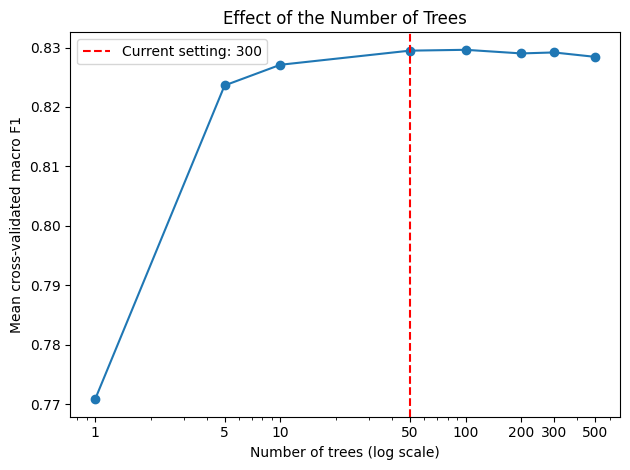

In [ ]:
tree_counts = [1, 5, 10, 50, 100, 200, 300, 500]
f1_by_size = []

for n in tree_counts:
    candidate = clone(model).set_params(classifier__n_estimators=n)

    f1 = cross_validate(
        candidate, X_train, y_train,
        cv=cv, scoring="f1_macro"
    )["test_score"]

    f1_by_size.append(f1.mean())

plt.plot(tree_counts, f1_by_size, marker="o")
plt.axvline(50, color="red", linestyle="--", label="Current setting: 300")
plt.xscale("log")
plt.xticks(tree_counts, tree_counts)
plt.xlabel("Number of trees (log scale)")
plt.ylabel("Mean cross-validated macro F1")
plt.title("Effect of the Number of Trees")
plt.legend()
plt.tight_layout()
plt.show()

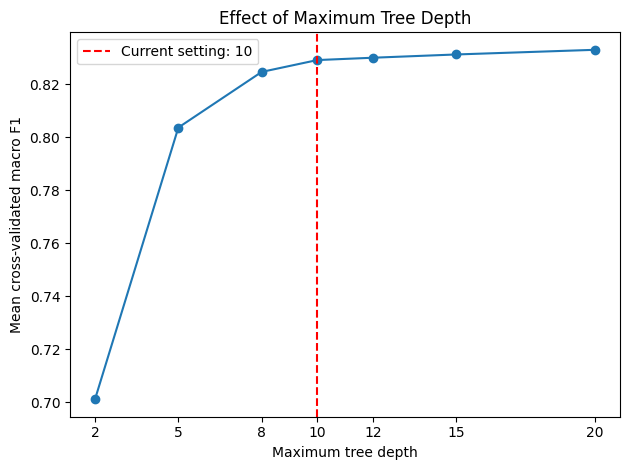

In [17]:
depths = [2, 5, 8, 10, 12, 15, 20]
f1_by_depth = []

for depth in depths:
    candidate = clone(model).set_params(classifier__max_depth=depth)

    f1 = cross_validate(
        candidate, X_train, y_train,
        cv=cv, scoring="f1_macro"
    )["test_score"]

    f1_by_depth.append(f1.mean())

plt.plot(depths, f1_by_depth, marker="o")
plt.axvline(10, color="red", linestyle="--", label="Current setting: 10")
plt.xticks(depths)
plt.xlabel("Maximum tree depth")
plt.ylabel("Mean cross-validated macro F1")
plt.title("Effect of Maximum Tree Depth")
plt.legend()
plt.tight_layout()
plt.savefig("mtd.png", dpi = 90)
plt.show()

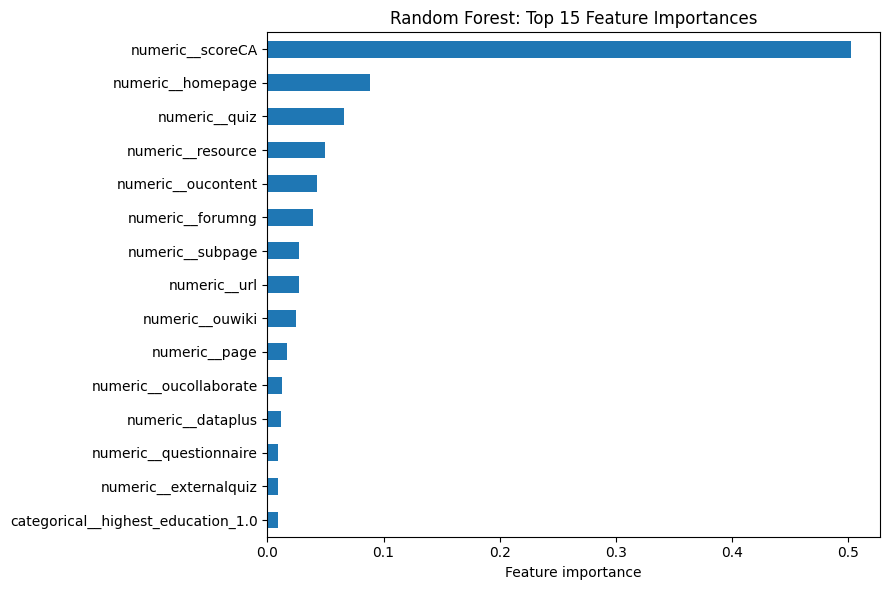

In [ ]:
processed_feature_names = (
    model.named_steps["preprocessor"].get_feature_names_out()
)

importances = pd.Series(
    model.named_steps["classifier"].feature_importances_,
    index=processed_feature_names
).sort_values()

importances.tail(15).plot.barh(figsize=(9, 6))

plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

Test accuracy: 0.870
Recall (Withdrawn/Fail): 0.689
Recall (Pass/Distinction): 0.953
                  precision    recall  f1-score   support

            Fail      0.870     0.689     0.769      1275
Pass/Distinction      0.869     0.953     0.909      2773

        accuracy                          0.870      4048
       macro avg      0.870     0.821     0.839      4048
    weighted avg      0.870     0.870     0.865      4048



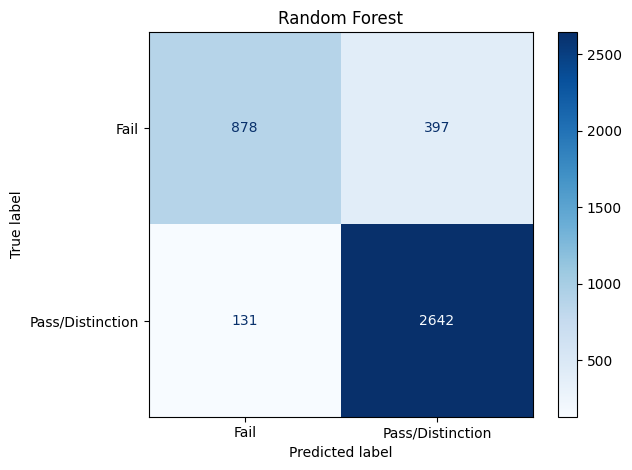

In [15]:
y_pred = model.predict(X_test)

forest_recall = recall_score(
    y_test, y_pred,
    labels=[0, 1],
    average=None,
    zero_division=0
)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Recall (Withdrawn/Fail): {forest_recall[0]:.3f}")
print(f"Recall (Pass/Distinction): {forest_recall[1]:.3f}")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    digits=3,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=class_names,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest")
plt.tight_layout()
plt.savefig("rf.png", dpi=300)
plt.show()